In [1]:
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from datetime import date
import re
from tqdm import tqdm
import time
from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr
from scipy.spatial.distance import jaccard, euclidean
import itertools
import functools
import operator

today = date.today()

In [2]:
pwd

'/home/stsai/AugmentedGenomics/externalresources/code'

# DHS-Gene Enrichment Scores

In [3]:
gata1_gene_dhsenrichment = pd.read_pickle('../output/GATA1-gene-dhs-enrichment_pearsonr.pkl')

In [9]:
gata1_gene_dhsenrichment

,index,Tissue invariant,Stromal A,Primitive / embryonic,Stromal B,Lymphoid,Renal / cancer,Placental / trophoblast,Neural,Cardiac,Organ devel. / renal,Pulmonary devel.,Musculoskeletal,Digestive,Vascular / endothelial,Myeloid / erythroid,Cancer / epithelial,GATA1_pearson_corr
11475,GATA1,0.807944,2.464814,0.458440,0.000000,0.000000,0.000000,0.512424,0.629713,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,13.346105,0.000000,1.000000
7303,MBD3L5,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.263091,0.000000,0.981445
12018,IFNA10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.263091,0.000000,0.981445
17699,CT45A10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.263091,0.000000,0.981445
17735,SPDYE6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.263091,0.000000,0.981445
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10058,PLEKHA1,1.235679,0.000000,0.233715,1.447652,1.530735,1.495284,1.306179,0.481545,2.185305,1.315316,0.762621,1.499167,1.181955,2.343743,0.179050,0.618562,-0.400197
12698,CEP112,0.762067,1.010807,0.817817,1.630321,1.022967,0.681604,0.777527,0.916758,0.966843,0.705374,1.410969,1.232754,1.825506,1.696811,0.201643,0.762959,-0.400252
455,MACROD2,0.757554,1.223518,0.622016,0.917604,0.810204,1.499091,0.768745,1.576819,1.063911,1.024573,1.188097,1.275914,1.309428,0.895932,0.193711,1.704262,-0.440585
16801,PTPRM,0.710617,1.374764,0.855604,1.325820,0.336925,1.552036,0.780474,1.296834,1.609229,0.922457,1.347801,1.331768,0.994715,1.413594,0.135617,0.971735,-0.441076


In [5]:
dhs_scores = np.load("../output/gene-dhs-distr.npy")
gene_dhs_scores = []
for i in range(len(dhs_scores)):
    gene_dhs_scores.extend(dhs_scores[i, i:])

In [76]:
def percentileofscore_dhs_gene_enrichment_all(score):
    percentile = percentileofscore(gene_dhs_scores, score)
    print(percentile)
    return percentile

gata1_gene_dhsenrichment['enrichment_score'] = gata1_gene_dhsenrichment['pearson_corr'].apply(percentileofscore_dhs_gene_enrichment_all)
gata1_gene_dhsenrichment.to_pickle('../output/GATA1-gene-dhs-enrichment_pearsonr.pkl')
print(gata1_gene_dhsenrichment)

99.99569504411083


KeyboardInterrupt: 

In [2]:
def getGeneAssociations(closest_gene):
    hg38_protein_assoc_sub = pd.read_pickle('../data/hg38-protein-associations.pkl')
    hg38_gene_df = process_bedfile('hg38')
    
    specific_gene_df = hg38_protein_assoc_sub[hg38_protein_assoc_sub['protein1_pref'] == closest_gene].sort_values('combined_score', ascending=False)

    specific_gene_info = hg38_gene_df.loc[specific_gene_df['protein2_pref'].tolist()].reset_index()
    specific_gene_info = specific_gene_info.drop_duplicates('gene_names')
    

    gene_insert = hg38_gene_df.loc[closest_gene]
    gene_insert['gene_names'] = closest_gene

    # Keep this line when commenting out the closest gene itself.
    specific_gene_info['combined_score'] = specific_gene_df['combined_score'].tolist()
    specific_gene_info = specific_gene_info.append(gene_insert)

    idx = [-1] + [i for i in range(len(specific_gene_info)-1)]
    specific_gene_info = specific_gene_info.reset_index().iloc[idx]


    specific_gene_info = specific_gene_info[['chr', 'start', 'end', 'gene_names', 'combined_score', 'descriptor']]
    return specific_gene_info


def process_bedfile(assembly):
    ## READ IN BED FILE WITH COORDINATES
    
    if assembly == 'hg19':
        gene_df = pd.read_csv('../data/hg19.gencode.v19.annotation.hgnc.longest.gtf.bed14',
                      delimiter='\t', header = None, index_col=3)
    elif assembly == 'hg38':
        gene_df = pd.read_csv('../data/hg38.gencode.v38.annotation.gtf.genePred.hgnc.longest.noChrM.bed',
                      delimiter='\t', header = None, index_col=3)
    
    genes_in_both = pd.read_pickle('../data/STRING-and-Alex-genes-' + assembly + '.pkl')
    
    gene_df = gene_df.rename({3:'gene_names', 0:'chr', 1:'start', 2:'end', 5:'strand', 9:'descriptor'}, axis=1)
    gene_df.index = gene_df.index.rename('gene_names')
    
    # Remove duplicate genes
    gene_df_no_dupes = gene_df[~gene_df.index.duplicated(keep='first')]
    print(gene_df_no_dupes.shape, gene_df.shape)

    # Remove duplicate genes from 'genes_in_both'
    genes_in_both_df = gene_df_no_dupes.loc[genes_in_both.preferred_name.tolist()].reset_index()
    genes_in_both_dup_removed = genes_in_both_df.drop_duplicates(subset=['gene_names'])
    print(genes_in_both_df.shape, genes_in_both_dup_removed.shape)
    genes_in_both_dup_removed.set_index('gene_names', inplace=True)
    return genes_in_both_dup_removed

def generate_ROI_url(fn, assembly):
    if assembly == 'hg19':
        return 'https://epilogos.altius.org:3001/?application=viewer&mode=single&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~stsai%2F' + fn
    elif assembly == 'hg38':
        return 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~stsai%2F' + fn

def getCombinedScore(coordinates):
    gene_bed = process_bedfile('hg38')
    
    goi_chrm = coordinates.split(' ')[0]
    goi_start = coordinates
    
    goi_chrm = gene_bed.loc[gene].chr
    goi_start = gene_bed.loc[gene].start - 5000
    goi_end = gene_bed.loc[gene].end + 1000
    
    # Get different types of datasets in this region
    
    # STRING
    hg38_gene_ranges_fn = open('../data/hg38_gene_ranges.pkl', "rb")
    hg38_gene_ranges = pickle.load(hg38_gene_ranges_fn)
    hg38_gene_ranges[goi_chrm]


    for i, interval in enumerate(hg38_gene_ranges[goi_chrm]):
        if goi_start in range(interval[0], interval[1]):
            gene1 = hg38_gene_ranges[goi_chrm][interval]
        if goi_end in range(interval[0], interval[1]):
            gene2 = hg38_gene_ranges[goi_chrm][interval]
       
    if gene1 == gene2:
        geneAssociations = getGeneAssociations(gene1)
    else:
        geneAssociations1 = getGeneAssociations(gene1)
        geneAssociations2 = getGeneAssociations(gene2)
    
    
    # Gene-DHS Enrichment
    gata1_gene_dhsenrichment = pd.read_pickle('../output/GATA1-gene-dhs-enrichment_pearsonr.pkl')
    

In [23]:
## Upstream of GATA1
GATA1_up_coord_1 = 'chrX 48781672'
GATA1_up_coord_2 = 'chrX 48795311'

goi_chrm = 'chrX'
goi_start = int('48781672') - 5000
goi_end = int('48795311') + 1000

hg38_gene_ranges_fn = open('../data/hg38_gene_ranges.pkl', "rb")
hg38_gene_ranges = pickle.load(hg38_gene_ranges_fn)
hg38_gene_ranges[goi_chrm]


for i, interval in enumerate(hg38_gene_ranges[goi_chrm]):
#     print(interval)
    if goi_start in range(interval[0], interval[1]):
        print(hg38_gene_ranges[goi_chrm][interval])
    if goi_end in range(interval[0], interval[1]):
        print(hg38_gene_ranges[goi_chrm][interval])
        

GATA1
GATA1


In [4]:
gata1_gene_dhsenrichment = pd.read_pickle('../output/GATA1-gene-dhs-enrichment_pearsonr.pkl')
# gata1_gene_dhsenrichment.loc['GATA1']

gene_DHS_enrichment = pd.read_pickle('../data/gene-dhs-enrichment-dropna.pkl')
gene_DHS_enrichment



,Tissue invariant,Stromal A,Primitive / embryonic,Stromal B,Lymphoid,Renal / cancer,Placental / trophoblast,Neural,Cardiac,Organ devel. / renal,Pulmonary devel.,Musculoskeletal,Digestive,Vascular / endothelial,Myeloid / erythroid,Cancer / epithelial
ARF5,8.752724,0.000000,0.993287,1.447652,0.000000,0.000000,0.000000,0.682189,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.521924,1.752594
M6PR,4.501401,3.051674,0.851389,0.620422,4.861347,1.815703,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.869671,0.000000
FKBP4,0.000000,0.000000,0.595972,2.316243,0.400346,1.694656,0.444101,0.000000,1.857510,4.472073,1.296456,0.566352,1.607459,0.000000,1.217539,0.701037
CYP26B1,0.477421,0.000000,3.115309,0.296111,0.000000,0.866585,0.605592,1.209334,1.266484,1.524570,0.000000,1.351522,0.000000,0.000000,0.000000,0.000000
NDUFAF7,3.000934,0.000000,0.851389,1.861266,1.715769,0.907851,0.475822,0.292367,0.000000,0.000000,1.389060,1.213611,0.861139,4.268960,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CERS1,0.287761,0.000000,1.551160,0.237970,0.987155,0.348217,0.365014,0.560703,0.000000,1.531532,0.000000,5.120443,0.660600,0.545803,1.000717,0.864293
ZNF518A,4.726471,0.000000,0.446979,1.085739,0.300260,0.635496,0.666151,0.409313,0.696566,1.118018,0.000000,0.424764,2.411189,3.984363,0.913155,1.577334
MUC5AC,0.359086,0.547736,3.412832,0.148477,0.513264,0.217264,2.391312,0.069968,0.000000,0.764457,0.000000,0.580874,1.030423,0.000000,0.156095,0.539260
EIF3L,2.838721,0.000000,0.000000,1.643280,0.324605,1.374045,1.440327,0.663751,0.000000,0.604334,2.102361,1.836817,1.303345,4.307419,0.493597,0.568409


In [5]:
fn = '../output/gene-dhs-distr.npy'
pearson_scores = np.load(fn)

gene_DHS_enrichment.loc['GATA1']
# gene_DHS_enrichment = gene_DHS_enrichment.reset_index()

Tissue invariant            0.807944
Stromal A                   2.464814
Primitive / embryonic       0.458440
Stromal B                   0.000000
Lymphoid                    0.000000
Renal / cancer              0.000000
Placental / trophoblast     0.512424
Neural                      0.629713
Cardiac                     0.000000
Organ devel. / renal        0.000000
Pulmonary devel.            0.000000
Musculoskeletal             0.000000
Digestive                   0.000000
Vascular / endothelial      0.000000
Myeloid / erythroid        13.346105
Cancer / epithelial         0.000000
Name: GATA1, dtype: float64

In [6]:
gene_DHS_enrichment = gene_DHS_enrichment.reset_index()
gene_DHS_enrichment[gene_DHS_enrichment['index']=='GATA1']

,index,Tissue invariant,Stromal A,Primitive / embryonic,Stromal B,Lymphoid,Renal / cancer,Placental / trophoblast,Neural,Cardiac,Organ devel. / renal,Pulmonary devel.,Musculoskeletal,Digestive,Vascular / endothelial,Myeloid / erythroid,Cancer / epithelial
11475,GATA1,0.807944,2.464814,0.45844,0.0,0.0,0.0,0.512424,0.629713,0.0,0.0,0.0,0.0,0.0,0.0,13.346105,0.0


In [7]:
gata1_scores = pearson_scores[11475]
len(gata1_scores)

gene_DHS_enrichment['GATA1_pearson_corr'] = gata1_scores
# gene_DHS_enrichment = gene_DHS_enrichment.drop(labels=['level_0'], axis=1)

gene_DHS_enrichment = gene_DHS_enrichment.sort_values(by=['GATA1_pearson_corr'], ascending=False)
gene_DHS_enrichment

,index,Tissue invariant,Stromal A,Primitive / embryonic,Stromal B,Lymphoid,Renal / cancer,Placental / trophoblast,Neural,Cardiac,Organ devel. / renal,Pulmonary devel.,Musculoskeletal,Digestive,Vascular / endothelial,Myeloid / erythroid,Cancer / epithelial,GATA1_pearson_corr
11475,GATA1,0.807944,2.464814,0.458440,0.000000,0.000000,0.000000,0.512424,0.629713,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,13.346105,0.000000,1.000000
7303,MBD3L5,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.263091,0.000000,0.981445
12018,IFNA10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.263091,0.000000,0.981445
17699,CT45A10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.263091,0.000000,0.981445
17735,SPDYE6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.263091,0.000000,0.981445
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10058,PLEKHA1,1.235679,0.000000,0.233715,1.447652,1.530735,1.495284,1.306179,0.481545,2.185305,1.315316,0.762621,1.499167,1.181955,2.343743,0.179050,0.618562,-0.400197
12698,CEP112,0.762067,1.010807,0.817817,1.630321,1.022967,0.681604,0.777527,0.916758,0.966843,0.705374,1.410969,1.232754,1.825506,1.696811,0.201643,0.762959,-0.400252
455,MACROD2,0.757554,1.223518,0.622016,0.917604,0.810204,1.499091,0.768745,1.576819,1.063911,1.024573,1.188097,1.275914,1.309428,0.895932,0.193711,1.704262,-0.440585
16801,PTPRM,0.710617,1.374764,0.855604,1.325820,0.336925,1.552036,0.780474,1.296834,1.609229,0.922457,1.347801,1.331768,0.994715,1.413594,0.135617,0.971735,-0.441076


## START HERE WHEN REOPENING FILE

In [3]:
# gene_DHS_enrichment.to_pickle('../output/GATA1-gene-dhs-enrichment_pearsonr.pkl')

gene_DHS_enrichment = pd.read_pickle('../output/GATA1-gene-dhs-enrichment_pearsonr.pkl')
print(gene_DHS_enrichment)

         index  Tissue invariant  Stromal A  Primitive / embryonic  Stromal B  \
11475    GATA1          0.807944   2.464814               0.458440   0.000000   
7303    MBD3L5          0.000000   0.000000               0.000000   0.000000   
12018   IFNA10          0.000000   0.000000               0.000000   0.000000   
17699  CT45A10          0.000000   0.000000               0.000000   0.000000   
17735   SPDYE6          0.000000   0.000000               0.000000   0.000000   
...        ...               ...        ...                    ...        ...   
10058  PLEKHA1          1.235679   0.000000               0.233715   1.447652   
12698   CEP112          0.762067   1.010807               0.817817   1.630321   
455    MACROD2          0.757554   1.223518               0.622016   0.917604   
16801    PTPRM          0.710617   1.374764               0.855604   1.325820   
5082     AXIN2          0.963603   0.000000               0.874821   1.035934   

       Lymphoid  Renal / ca

In [4]:
hg38_genes = process_bedfile('hg38')
gene_DHS_enrichment = gene_DHS_enrichment.set_index(gene_DHS_enrichment['index'])
# print(gene_DHS_enrichment)
GATA1_gene_enrichments = hg38_genes.loc[gene_DHS_enrichment['index']]
GATA1_gene_enrichments['GATA1_pearson_corr'] = gene_DHS_enrichment['GATA1_pearson_corr']
GATA1_gene_enrichments['gene_names'] = GATA1_gene_enrichments.index
GATA1_gene_enrichments = GATA1_gene_enrichments[['chr', 'start', 'end', 'gene_names', 'GATA1_pearson_corr']]
GATA1_gene_enrichments

(40175, 13) (41315, 13)
(18025, 14) (18025, 14)


,chr,start,end,gene_names,GATA1_pearson_corr
gene_names,,,,,
GATA1,chrX,48786572,48794311,GATA1,1.000000
MBD3L5,chr19,7030577,7033011,MBD3L5,0.981445
IFNA10,chr9,21206180,21207143,IFNA10,0.981445
CT45A10,chrX,135881064,135893444,CT45A10,0.981445
SPDYE6,chr7,102345745,102356444,SPDYE6,0.981445
...,...,...,...,...,...
PLEKHA1,chr10,122374695,122442602,PLEKHA1,-0.400197
CEP112,chr17,65635536,66192133,CEP112,-0.400252
MACROD2,chr20,13995368,16053197,MACROD2,-0.440585


In [95]:
gene_DHS_enrichment

,index,Tissue invariant,Stromal A,Primitive / embryonic,Stromal B,Lymphoid,Renal / cancer,Placental / trophoblast,Neural,Cardiac,Organ devel. / renal,Pulmonary devel.,Musculoskeletal,Digestive,Vascular / endothelial,Myeloid / erythroid,Cancer / epithelial,GATA1_pearson_corr
index,,,,,,,,,,,,,,,,,,
GATA1,GATA1,0.807944,2.464814,0.458440,0.000000,0.000000,0.000000,0.512424,0.629713,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,13.346105,0.000000,1.000000
MBD3L5,MBD3L5,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.263091,0.000000,0.981445
IFNA10,IFNA10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.263091,0.000000,0.981445
CT45A10,CT45A10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.263091,0.000000,0.981445
SPDYE6,SPDYE6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.263091,0.000000,0.981445
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PLEKHA1,PLEKHA1,1.235679,0.000000,0.233715,1.447652,1.530735,1.495284,1.306179,0.481545,2.185305,1.315316,0.762621,1.499167,1.181955,2.343743,0.179050,0.618562,-0.400197
CEP112,CEP112,0.762067,1.010807,0.817817,1.630321,1.022967,0.681604,0.777527,0.916758,0.966843,0.705374,1.410969,1.232754,1.825506,1.696811,0.201643,0.762959,-0.400252
MACROD2,MACROD2,0.757554,1.223518,0.622016,0.917604,0.810204,1.499091,0.768745,1.576819,1.063911,1.024573,1.188097,1.275914,1.309428,0.895932,0.193711,1.704262,-0.440585


In [94]:
GATA1_gene_enrichments_bed = BedTool.from_dataframe(GATA1_gene_enrichments)
fn = '/home/stsai/public_html/hg38_GATA1-5kb-1kb_associated_proteins-dhs-enrichments.bed'
GATA1_gene_enrichments_bed.saveas(fn)


print(generate_ROI_url('hg38_GATA1-5kb-1kb_associated_proteins-dhs-enrichments.bed', 'hg38'))

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~stsai%2Fhg38_GATA1-5kb-1kb_associated_proteins-dhs-enrichments.bed


In [134]:
gata1_string_df = getGeneAssociations('GATA1')

(40175, 13) (41315, 13)
(18025, 14) (18025, 14)


/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/series.py:1056: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cacher_needs_updating = self._check_is_chained_assignment_possible()
/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/indexing.py:1724: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_with_indexer_missing(indexer, value)


In [135]:
gata1_string_df = gata1_string_df.rename(columns={'combined_score':'STRING_score'})
gata1_string_df[:10]

,chr,start,end,gene_names,STRING_score,descriptor
1728,chrX,48786572,48794311,GATA1,NaN,GATA binding protein 1
0,chr1,47216289,47231715,TAL1,999.0,"TAL bHLH transcription factor 1, erythroid dif..."
1,chr16,88453279,88537031,ZFPM1,999.0,"zinc finger protein, FOG family member 1"
2,chr11,33858575,33892076,LMO2,999.0,LIM domain only 2
3,chr9,134030304,134068026,BRD3,996.0,bromodomain containing 3
4,chr10,102106488,102120368,LDB1,996.0,LIM domain binding 1
5,chr11,47354859,47378547,SPI1,995.0,Spi-1 proto-oncogene
6,chr22,41092591,41180077,EP300,994.0,E1A binding protein p300
7,chr19,1609291,1652615,TCF3,990.0,transcription factor 3
8,chr4,16501540,16898645,LDB2,988.0,LIM domain binding 2


In [9]:
gata1_string_df = gata1_string_df.set_index(gata1_string_df['gene_names'])

print(GATA1_gene_enrichments)
print(gata1_string_df)

print(GATA1_gene_enrichments.index.intersection(gata1_string_df.index))

              chr      start        end gene_names  GATA1_pearson_corr
gene_names                                                            
GATA1        chrX   48786572   48794311      GATA1            1.000000
MBD3L5      chr19    7030577    7033011     MBD3L5            0.981445
IFNA10       chr9   21206180   21207143     IFNA10            0.981445
CT45A10      chrX  135881064  135893444    CT45A10            0.981445
SPDYE6       chr7  102345745  102356444     SPDYE6            0.981445
...           ...        ...        ...        ...                 ...
PLEKHA1     chr10  122374695  122442602    PLEKHA1           -0.400197
CEP112      chr17   65635536   66192133     CEP112           -0.400252
MACROD2     chr20   13995368   16053197    MACROD2           -0.440585
PTPRM       chr18    7566781    8406861      PTPRM           -0.441076
AXIN2       chr17   65528562   65561648      AXIN2           -0.446542

[17765 rows x 5 columns]
              chr      start        end gene_names 

In [112]:
intersecting_indices = GATA1_gene_enrichments.index.intersection(gata1_string_df.index)
intersecting_indices

Index(['GATA1', 'TRIM58', 'LMO2', 'TFRC', 'HBB', 'HEMGN', 'MPO', 'HBD', 'GYPE',
       'MYB',
       ...
       'ITIH6', 'KCNH5', 'HSPA2', 'KLF12', 'HES7', 'TCF7L1', 'TFEB', 'ZNF219',
       'JAG1', 'SMAD6'],
      dtype='object', name='gene_names', length=1717)

In [118]:
gata1_string_df = gata1_string_df.rename(columns={'combined_score':'STRING_score'})
gata1_string_df

,chr,start,end,gene_names,STRING_score,descriptor
gene_names,,,,,,
GATA1,chrX,48786572,48794311,GATA1,NaN,GATA binding protein 1
TAL1,chr1,47216289,47231715,TAL1,999.0,"TAL bHLH transcription factor 1, erythroid dif..."
ZFPM1,chr16,88453279,88537031,ZFPM1,999.0,"zinc finger protein, FOG family member 1"
LMO2,chr11,33858575,33892076,LMO2,999.0,LIM domain only 2
BRD3,chr9,134030304,134068026,BRD3,996.0,bromodomain containing 3
...,...,...,...,...,...,...
HMOX1,chr22,35381092,35394214,HMOX1,150.0,heme oxygenase 1
ATM,chr11,108223066,108369102,ATM,150.0,ATM serine/threonine kinase
CES1,chr16,55802853,55833337,CES1,150.0,carboxylesterase 1


In [138]:
combined_df = GATA1_gene_enrichments.loc[intersecting_indices]
combined_df['STRING_score'] = gata1_string_df['STRING_score']
combined_df

,chr,start,end,gene_names,GATA1_pearson_corr,STRING_score
gene_names,,,,,,
GATA1,chrX,48786572,48794311,GATA1,1.000000,NaN
TRIM58,chr1,247857186,247880138,TRIM58,0.976969,234.0
LMO2,chr11,33858575,33892076,LMO2,0.974980,999.0
TFRC,chr3,196049283,196082094,TFRC,0.973597,610.0
HBB,chr11,5226619,5229395,HBB,0.973268,958.0
...,...,...,...,...,...,...
TCF7L1,chr2,85133391,85310387,TCF7L1,-0.317019,182.0
TFEB,chr6,41683977,41736259,TFEB,-0.320954,190.0
ZNF219,chr14,21090081,21104722,ZNF219,-0.332880,191.0


In [139]:
leftover_dhs_enrichment = GATA1_gene_enrichments[~GATA1_gene_enrichments['gene_names'].isin(intersecting_indices)]
leftover_dhs_enrichment = leftover_dhs_enrichment.drop_duplicates(subset='gene_names')
leftover_dhs_enrichment

,chr,start,end,gene_names,GATA1_pearson_corr
gene_names,,,,,
MBD3L5,chr19,7030577,7033011,MBD3L5,0.981445
IFNA10,chr9,21206180,21207143,IFNA10,0.981445
CT45A10,chrX,135881064,135893444,CT45A10,0.981445
SPDYE6,chr7,102345745,102356444,SPDYE6,0.981445
CT45A3,chrX,135760043,135768191,CT45A3,0.981445
...,...,...,...,...,...
PLEKHA1,chr10,122374695,122442602,PLEKHA1,-0.400197
CEP112,chr17,65635536,66192133,CEP112,-0.400252
MACROD2,chr20,13995368,16053197,MACROD2,-0.440585


In [147]:
leftover_string = gata1_string_df[~gata1_string_df['gene_names'].isin(intersecting_indices)]
leftover_string

,chr,start,end,gene_names,STRING_score,descriptor
1728,chrX,48786572,48794311,GATA1,NaN,GATA binding protein 1
210,chr17,35871490,35880495,CCL5,462.0,C-C motif chemokine ligand 5
274,chr16,29443055,29454562,BOLA2,420.0,bolA family member 2
275,chr16,30192934,30194306,BOLA2B,420.0,bolA family member 2B
381,chr17,64319414,64390860,PECAM1,355.0,platelet and endothelial cell adhesion molecule 1
494,chr17,36013057,36017972,CCL23,306.0,C-C motif chemokine ligand 23
840,chr17,36937474,36944612,LHX1,229.0,LIM homeobox 1
1070,chrX,120158612,120165630,RHOXF2,197.0,Rhox homeobox family member 2
1074,chr20,43914851,44069616,TOX2,197.0,TOX high mobility group box family member 2
1079,chr16,29443269,29454651,BOLA2-SMG1P6,196.0,BOLA2-SMG1P6 readthrough


In [141]:
combined_df = pd.concat([combined_df, leftover_dhs_enrichment], axis=0)
combined_df = pd.concat([combined_df, leftover_string], axis=0)
combined_df

,chr,start,end,gene_names,GATA1_pearson_corr,STRING_score,descriptor
gene_names,,,,,,,
GATA1,chrX,48786572,48794311,GATA1,1.000000,NaN,NaN
TRIM58,chr1,247857186,247880138,TRIM58,0.976969,234.0,NaN
LMO2,chr11,33858575,33892076,LMO2,0.974980,999.0,NaN
TFRC,chr3,196049283,196082094,TFRC,0.973597,610.0,NaN
HBB,chr11,5226619,5229395,HBB,0.973268,958.0,NaN
...,...,...,...,...,...,...,...
FOXD4L3,chr9,68302866,68305084,FOXD4L3,NaN,164.0,forkhead box D4 like 3
FOXD4L6,chr9,41126434,41128681,FOXD4L6,NaN,164.0,forkhead box D4 like 6
HSFX1,chrX,149774067,149776867,HSFX1,NaN,163.0,"heat shock transcription factor family, X-link..."


In [10]:
# combined_df.to_pickle('../output/dhs-enrichment-STRING-combined-df.pkl')
combined_df = pd.read_pickle('../output/dhs-enrichment-STRING-combined-df.pkl')
print(combined_df)
len(list(set(combined_df.index)))

              chr      start        end gene_names  GATA1_pearson_corr  \
gene_names                                                               
GATA1        chrX   48786572   48794311      GATA1            1.000000   
TRIM58       chr1  247857186  247880138     TRIM58            0.976969   
LMO2        chr11   33858575   33892076       LMO2            0.974980   
TFRC         chr3  196049283  196082094       TFRC            0.973597   
HBB         chr11    5226619    5229395        HBB            0.973268   
...           ...        ...        ...        ...                 ...   
FOXD4L3      chr9   68302866   68305084    FOXD4L3                 NaN   
FOXD4L6      chr9   41126434   41128681    FOXD4L6                 NaN   
HSFX1        chrX  149774067  149776867      HSFX1                 NaN   
HSFX2        chrX  149592511  149595314      HSFX2                 NaN   
GAGE12F      chrX   49551277   49568218    GAGE12F                 NaN   

            STRING_score             

17777

In [143]:
print(combined_df.groupby(combined_df.index,as_index=False).size())
print(leftover_string.groupby(leftover_string.index,as_index=False).size().sort_values(by='size',ascending=False))
print(leftover_dhs_enrichment.groupby(leftover_dhs_enrichment.index,as_index=False).size().sort_values(by='size',ascending=False))

      gene_names  size
0           A1BG     1
1           A1CF     1
2            A2M     1
3          A2ML1     1
4        A3GALT2     1
...          ...   ...
17772     ZYG11A     1
17773     ZYG11B     1
17774        ZYX     1
17775      ZZEF1     1
17776       ZZZ3     1

[17777 rows x 2 columns]
      gene_names  size
0          BOLA2     1
1   BOLA2-SMG1P6     1
2         BOLA2B     1
3        FOXD4L3     1
4        FOXD4L6     1
5        GAGE12F     1
6          HSFX1     1
7          HSFX2     1
8         RHOXF2     1
9        RHOXF2B     1
10          TOX2     1
11      ZSCAN5DP     1
      gene_names  size
0           A1BG     1
10703    PRPF38A     1
10690     PROKR1     1
10691     PROKR2     1
10692      PROM2     1
...          ...   ...
5354       GNRH1     1
5355       GNRH2     1
5356       GNRHR     1
5357         GNS     1
16047       ZZZ3     1

[16048 rows x 2 columns]


In [11]:
combined_df['GATA1_pearson_corr'] = combined_df['GATA1_pearson_corr'].fillna(0)
combined_df['STRING_score'] = combined_df['STRING_score'].fillna(0)
print(combined_df)

combined_df[combined_df['GATA1_pearson_corr'] < 0] = 0
print(combined_df['STRING_score'])
combined_df['combined_score'] = 1.0-((1.0-(combined_df['STRING_score']/1000))*(1.0-combined_df['GATA1_pearson_corr']))
print(combined_df)

              chr      start        end gene_names  GATA1_pearson_corr  \
gene_names                                                               
GATA1        chrX   48786572   48794311      GATA1            1.000000   
TRIM58       chr1  247857186  247880138     TRIM58            0.976969   
LMO2        chr11   33858575   33892076       LMO2            0.974980   
TFRC         chr3  196049283  196082094       TFRC            0.973597   
HBB         chr11    5226619    5229395        HBB            0.973268   
...           ...        ...        ...        ...                 ...   
FOXD4L3      chr9   68302866   68305084    FOXD4L3            0.000000   
FOXD4L6      chr9   41126434   41128681    FOXD4L6            0.000000   
HSFX1        chrX  149774067  149776867      HSFX1            0.000000   
HSFX2        chrX  149592511  149595314      HSFX2            0.000000   
GAGE12F      chrX   49551277   49568218    GAGE12F            0.000000   

            STRING_score             

In [12]:
top100_combined_df = combined_df.sort_values(by='combined_score', ascending=False)[:100]
top100_combined_df = top100_combined_df[['chr', 'start', 'end', 'gene_names', 'GATA1_pearson_corr', 'STRING_score', 'combined_score']]
top100_combined_df

,chr,start,end,gene_names,GATA1_pearson_corr,STRING_score,combined_score
gene_names,,,,,,,
GATA1,chrX,48786572,48794311,GATA1,1.000000,0.0,1.000000
LMO2,chr11,33858575,33892076,LMO2,0.974980,999.0,0.999975
ZFPM1,chr16,88453279,88537031,ZFPM1,0.651799,999.0,0.999652
TAL1,chr1,47216289,47231715,TAL1,0.446585,999.0,0.999447
MYB,chr6,135181307,135219172,MYB,0.961418,983.0,0.999344
...,...,...,...,...,...,...,...
AGO4,chr1,35808015,35857890,AGO4,0.027776,907.0,0.909583
IL1B,chr2,112829750,112836779,IL1B,0.875038,257.0,0.907153
YBX1,chr1,42682417,42703805,YBX1,0.875913,237.0,0.905322


In [174]:
top100_combined_bed = BedTool.from_dataframe(top100_combined_df)
fn = '/home/stsai/public_html/hg38_GATA1-5kb-1kb_associated_proteins-STRING-dhs-enrichments.bed'
top100_combined_bed.saveas(fn)


print(generate_ROI_url('hg38_GATA1-5kb-1kb_associated_proteins-STRING-dhs-enrichments.bed', 'hg38'))

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~stsai%2Fhg38_GATA1-5kb-1kb_associated_proteins-STRING-dhs-enrichments.bed


In [13]:
top100_combined_df[:10]

,chr,start,end,gene_names,GATA1_pearson_corr,STRING_score,combined_score
gene_names,,,,,,,
GATA1,chrX,48786572,48794311,GATA1,1.000000,0.0,1.000000
LMO2,chr11,33858575,33892076,LMO2,0.974980,999.0,0.999975
ZFPM1,chr16,88453279,88537031,ZFPM1,0.651799,999.0,0.999652
TAL1,chr1,47216289,47231715,TAL1,0.446585,999.0,0.999447
MYB,chr6,135181307,135219172,MYB,0.961418,983.0,0.999344
HBB,chr11,5226619,5229395,HBB,0.973268,958.0,0.998877
NFE2,chr12,54292110,54301015,NFE2,0.943504,951.0,0.997232
AHSP,chr16,31527899,31528803,AHSP,0.915183,966.0,0.997116
LDB1,chr10,102106488,102120368,LDB1,0.076593,996.0,0.996306


# Horizontal Barplot

gene_names
LMO2     99.9
ZFPM1    99.9
TAL1     99.9
MYB      98.3
HBB      95.8
NFE2     95.1
AHSP     96.6
LDB1     99.6
Name: STRING_score, dtype: float64


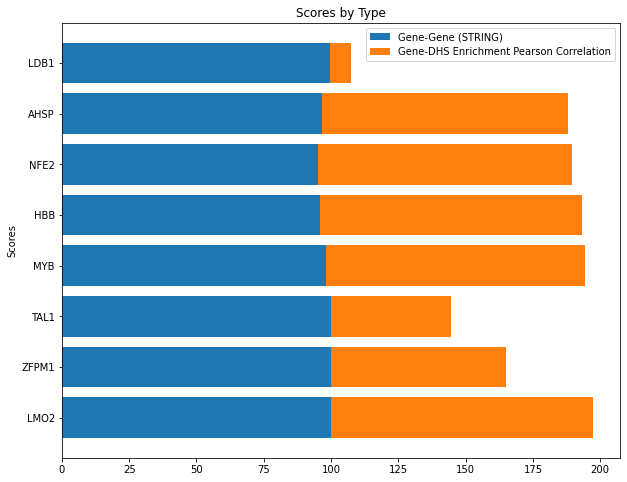

In [23]:
width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(10, 8))
labels = top100_combined_df.index[1:9]
print((top100_combined_df['STRING_score']/10)[1:9])

ax.barh(labels, (top100_combined_df['STRING_score']/10)[1:9], width, label='Gene-Gene (STRING)')
ax.barh(labels, (top100_combined_df['GATA1_pearson_corr']*100)[1:9], width, left=((top100_combined_df['STRING_score']/10)[1:9].tolist()),
       label='Gene-DHS Enrichment Pearson Correlation')

ax.set_ylabel('Scores')
ax.set_title('Scores by Type')
ax.legend()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_GATA1-top8-combined-score-barplot.png')

In [5]:
gata1_individual_scores = pd.read_pickle('../data/GATA1_top-STRING-associations-s3-individual.pkl')

gata1_individual_scores = gata1_individual_scores[['protein2_pref', 'coexpression', 'experimental', 'database', 'textmining']]
gata1_individual_scores = gata1_individual_scores.set_index('protein2_pref')

gene_bed = process_bedfile('hg38')
# print(gene_bed)

gata1_individual_scores['chr'] = gata1_individual_scores.index.map(gene_bed['chr'])
gata1_individual_scores['start'] = gata1_individual_scores.index.map(gene_bed['start'])
gata1_individual_scores['end'] = gata1_individual_scores.index.map(gene_bed['end'])

gata1_individual_scores = gata1_individual_scores[['chr', 'start', 'end', 'coexpression', 'experimental', 'database', 'textmining']]

gata1_individual_scores

(40175, 13) (41315, 13)
(18025, 14) (18025, 14)


,chr,start,end,coexpression,experimental,database,textmining
protein2_pref,,,,,,,
ZFPM1,chr16,88453279.0,88537031.0,0.0,828.0,900.0,990.0
LMO2,chr11,33858575.0,33892076.0,192.0,896.0,600.0,991.0
TAL1,chr1,47216289.0,47231715.0,232.0,735.0,600.0,991.0
BRD3,chr9,134030304.0,134068026.0,53.0,828.0,0.0,978.0
LDB1,chr10,102106488.0,102120368.0,0.0,245.0,600.0,990.0
...,...,...,...,...,...,...,...
ENTPD4,chr8,23385782.0,23457695.0,0.0,0.0,0.0,151.0
XK,chrX,37685790.0,37732130.0,118.0,0.0,0.0,77.0
TNFRSF1A,chr12,6328756.0,6342114.0,0.0,0.0,0.0,151.0


In [6]:
GATA1_gene_enrichments['GATA1_pearson_corr'] = GATA1_gene_enrichments['GATA1_pearson_corr'] * 1000
GATA1_gene_enrichments

,chr,start,end,gene_names,GATA1_pearson_corr
gene_names,,,,,
GATA1,chrX,48786572,48794311,GATA1,1000.000000
MBD3L5,chr19,7030577,7033011,MBD3L5,981.445404
IFNA10,chr9,21206180,21207143,IFNA10,981.445404
CT45A10,chrX,135881064,135893444,CT45A10,981.445404
SPDYE6,chr7,102345745,102356444,SPDYE6,981.445404
...,...,...,...,...,...
PLEKHA1,chr10,122374695,122442602,PLEKHA1,-400.197485
CEP112,chr17,65635536,66192133,CEP112,-400.252435
MACROD2,chr20,13995368,16053197,MACROD2,-440.585113


In [7]:
GATA1_gene_enrichments

,chr,start,end,gene_names,GATA1_pearson_corr
gene_names,,,,,
GATA1,chrX,48786572,48794311,GATA1,1000.000000
MBD3L5,chr19,7030577,7033011,MBD3L5,981.445404
IFNA10,chr9,21206180,21207143,IFNA10,981.445404
CT45A10,chrX,135881064,135893444,CT45A10,981.445404
SPDYE6,chr7,102345745,102356444,SPDYE6,981.445404
...,...,...,...,...,...
PLEKHA1,chr10,122374695,122442602,PLEKHA1,-400.197485
CEP112,chr17,65635536,66192133,CEP112,-400.252435
MACROD2,chr20,13995368,16053197,MACROD2,-440.585113


In [8]:
GATA1_gene_enrichments['GATA1_pearson_corr'][GATA1_gene_enrichments['GATA1_pearson_corr'] < 0] = 0
GATA1_gene_enrichments

/tmp/ipykernel_112803/2650302316.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  GATA1_gene_enrichments['GATA1_pearson_corr'][GATA1_gene_enrichments['GATA1_pearson_corr'] < 0] = 0


,chr,start,end,gene_names,GATA1_pearson_corr
gene_names,,,,,
GATA1,chrX,48786572,48794311,GATA1,1000.000000
MBD3L5,chr19,7030577,7033011,MBD3L5,981.445404
IFNA10,chr9,21206180,21207143,IFNA10,981.445404
CT45A10,chrX,135881064,135893444,CT45A10,981.445404
SPDYE6,chr7,102345745,102356444,SPDYE6,981.445404
...,...,...,...,...,...
PLEKHA1,chr10,122374695,122442602,PLEKHA1,0.000000
CEP112,chr17,65635536,66192133,CEP112,0.000000
MACROD2,chr20,13995368,16053197,MACROD2,0.000000


**CREATE COMBINED DATAFRAME**

In [9]:
intersecting_indices = GATA1_gene_enrichments.index.intersection(gata1_individual_scores.index)
intersecting_indices

Index(['TRIM58', 'LMO2', 'TFRC', 'HBB', 'HEMGN', 'MPO', 'HBD', 'GYPE', 'MYB',
       'HBA2',
       ...
       'ITIH6', 'KCNH5', 'HSPA2', 'KLF12', 'HES7', 'TCF7L1', 'TFEB', 'ZNF219',
       'JAG1', 'SMAD6'],
      dtype='object', length=1707)

In [10]:
GATA1_gene_enrichments = GATA1_gene_enrichments.rename(columns={'GATA1_pearson_corr':'coregulation'})

combined_df = gata1_individual_scores.loc[intersecting_indices]
# combined_df['STRING_score'] = gata1_string_df['STRING_score']
combined_df['coregulation'] = GATA1_gene_enrichments.loc[intersecting_indices]['coregulation']
combined_df

,chr,start,end,coexpression,experimental,database,textmining,coregulation
TRIM58,chr1,247857186.0,247880138.0,88.0,70.0,0.0,170.0,976.968883
LMO2,chr11,33858575.0,33892076.0,192.0,896.0,600.0,991.0,974.980103
TFRC,chr3,196049283.0,196082094.0,62.0,0.0,0.0,602.0,973.597313
HBB,chr11,5226619.0,5229395.0,88.0,67.0,900.0,571.0,973.268453
HEMGN,chr9,97926790.0,97944856.0,348.0,270.0,0.0,390.0,972.172623
...,...,...,...,...,...,...,...,...
TCF7L1,chr2,85133391.0,85310387.0,0.0,0.0,0.0,182.0,0.000000
TFEB,chr6,41683977.0,41736259.0,0.0,60.0,0.0,174.0,0.000000
ZNF219,chr14,21090081.0,21104722.0,0.0,78.0,0.0,159.0,0.000000
JAG1,chr20,10637683.0,10673999.0,0.0,78.0,0.0,187.0,0.000000


In [11]:
leftover_string = gata1_individual_scores[~gata1_individual_scores.index.isin(intersecting_indices)]
leftover_string

,chr,start,end,coexpression,experimental,database,textmining
protein2_pref,,,,,,,
H2AFZ,NaN,NaN,NaN,0.0,56.0,600.0,258.0
HIST2H2BE,NaN,NaN,NaN,0.0,78.0,600.0,233.0
HIST2H2AC,NaN,NaN,NaN,0.0,0.0,600.0,213.0
HIST1H2BK,NaN,NaN,NaN,60.0,78.0,600.0,0.0
HIST1H2BN,NaN,NaN,NaN,0.0,78.0,600.0,53.0
HIST2H3PS2,NaN,NaN,NaN,0.0,101.0,0.0,593.0
H2BFS,NaN,NaN,NaN,0.0,78.0,600.0,0.0
HIST1H2BJ,NaN,NaN,NaN,0.0,78.0,600.0,0.0
HIST1H2BA,NaN,NaN,NaN,0.0,78.0,600.0,0.0


In [12]:
leftover_enrichment = GATA1_gene_enrichments[~GATA1_gene_enrichments.index.isin(intersecting_indices)]
print(leftover_enrichment.shape)


# ensure that all leftover enrichment genes are protein-coding genes
protein_assoc_sub = pd.read_pickle('../data/hg38-protein-associations.pkl')
list1 = list(set(protein_assoc_sub.protein1_pref.tolist()))
print(len(list1))
list2 = list(set(protein_assoc_sub.protein2_pref.tolist()))
print(len(list2))
protein_coding_genes = list(set(list1 + list2))
print(len(protein_coding_genes))


# print(leftover_enrichment.index)
leftover_enrichment = leftover_enrichment[leftover_enrichment.index.isin(protein_coding_genes)]
print(leftover_enrichment.shape)
# leftover_enrichment

(16058, 5)
18007
18007
18007
(16046, 5)


In [13]:
# combined_df = pd.concat([combined_df, leftover_enrichment], axis=0)
combined_df = pd.concat([combined_df, leftover_string], axis=0)

combined_df['coregulation'] = combined_df['coregulation'].fillna(0)
combined_df['coexpression'] = combined_df['coexpression'].fillna(0)
combined_df['database'] = combined_df['database'].fillna(0)
combined_df['textmining'] = combined_df['textmining'].fillna(0)
combined_df['experimental'] = combined_df['experimental'].fillna(0)

# combined_df = combined_df.drop('gene_names', axis=1)
combined_df

,chr,start,end,coexpression,experimental,database,textmining,coregulation
TRIM58,chr1,247857186.0,247880138.0,88.0,70.0,0.0,170.0,976.968883
LMO2,chr11,33858575.0,33892076.0,192.0,896.0,600.0,991.0,974.980103
TFRC,chr3,196049283.0,196082094.0,62.0,0.0,0.0,602.0,973.597313
HBB,chr11,5226619.0,5229395.0,88.0,67.0,900.0,571.0,973.268453
HEMGN,chr9,97926790.0,97944856.0,348.0,270.0,0.0,390.0,972.172623
...,...,...,...,...,...,...,...,...
RARS,NaN,NaN,NaN,0.0,0.0,0.0,160.0,0.000000
HIST1H3H,NaN,NaN,NaN,69.0,101.0,0.0,76.0,0.000000
BHMG1,NaN,NaN,NaN,0.0,143.0,0.0,58.0,0.000000
CBSL,NaN,NaN,NaN,0.0,0.0,0.0,152.0,0.000000


In [14]:
combined_df['combined_score'] = (1-((1-combined_df['coexpression']/1000)*(1-combined_df['experimental']/1000)*(1-combined_df['database']/1000)*(1-combined_df['textmining']/1000)*(1-combined_df['coregulation']/1000)))*1000
combined_df

,chr,start,end,coexpression,experimental,database,textmining,coregulation,combined_score
TRIM58,chr1,247857186.0,247880138.0,88.0,70.0,0.0,170.0,976.968883,983.786720
LMO2,chr11,33858575.0,33892076.0,192.0,896.0,600.0,991.0,974.980103,999.992431
TFRC,chr3,196049283.0,196082094.0,62.0,0.0,0.0,602.0,973.597313,990.143243
HBB,chr11,5226619.0,5229395.0,88.0,67.0,900.0,571.0,973.268453,999.024207
HEMGN,chr9,97926790.0,97944856.0,348.0,270.0,0.0,390.0,972.172623,991.920722
...,...,...,...,...,...,...,...,...,...
RARS,NaN,NaN,NaN,0.0,0.0,0.0,160.0,0.000000,160.000000
HIST1H3H,NaN,NaN,NaN,69.0,101.0,0.0,76.0,0.000000,226.640644
BHMG1,NaN,NaN,NaN,0.0,143.0,0.0,58.0,0.000000,192.706000
CBSL,NaN,NaN,NaN,0.0,0.0,0.0,152.0,0.000000,152.000000


In [15]:
combined_df = combined_df.sort_values(by='combined_score', ascending=False)


In [16]:
# combined_df = combined_df.drop(index='GATA1')
top100_combined_df = combined_df
top100_combined_df

,chr,start,end,coexpression,experimental,database,textmining,coregulation,combined_score
LMO2,chr11,33858575.0,33892076.0,192.0,896.0,600.0,991.0,974.980103,999.992431
ZFPM1,chr16,88453279.0,88537031.0,0.0,828.0,900.0,990.0,651.798890,999.940109
TAL1,chr1,47216289.0,47231715.0,232.0,735.0,600.0,991.0,446.585475,999.594529
MYB,chr6,135181307.0,135219172.0,140.0,82.0,900.0,817.0,961.417809,999.442584
HBB,chr11,5226619.0,5229395.0,88.0,67.0,900.0,571.0,973.268453,999.024207
...,...,...,...,...,...,...,...,...,...
B2M,chr15,44711508.0,44718851.0,0.0,0.0,0.0,151.0,0.000000,151.000000
DPP10,chr2,114442640.0,115845780.0,0.0,0.0,0.0,151.0,0.000000,151.000000
ATM,chr11,108223066.0,108369102.0,0.0,0.0,0.0,151.0,0.000000,151.000000
IHH,chr2,219054423.0,219060921.0,0.0,0.0,0.0,151.0,0.000000,151.000000


In [17]:
top100_combined_df['total'] = (top100_combined_df[['coexpression', 'experimental', 'database', 'textmining', 'coregulation']].sum(axis=1))
# print(top100_combined_df)

columns = ['textmining', 'coexpression', 'database', 'experimental', 'coregulation']

for c in columns:
    top100_combined_df[c+'_fraction'] = top100_combined_df[c].divide(top100_combined_df['total']).multiply(top100_combined_df['combined_score'])
    
print(top100_combined_df)
                    

          chr        start          end  coexpression  experimental  database  \
LMO2    chr11   33858575.0   33892076.0         192.0         896.0     600.0   
ZFPM1   chr16   88453279.0   88537031.0           0.0         828.0     900.0   
TAL1     chr1   47216289.0   47231715.0         232.0         735.0     600.0   
MYB      chr6  135181307.0  135219172.0         140.0          82.0     900.0   
HBB     chr11    5226619.0    5229395.0          88.0          67.0     900.0   
...       ...          ...          ...           ...           ...       ...   
B2M     chr15   44711508.0   44718851.0           0.0           0.0       0.0   
DPP10    chr2  114442640.0  115845780.0           0.0           0.0       0.0   
ATM     chr11  108223066.0  108369102.0           0.0           0.0       0.0   
IHH      chr2  219054423.0  219060921.0           0.0           0.0       0.0   
ENTPD4   chr8   23385782.0   23457695.0           0.0           0.0       0.0   

        textmining  coregul

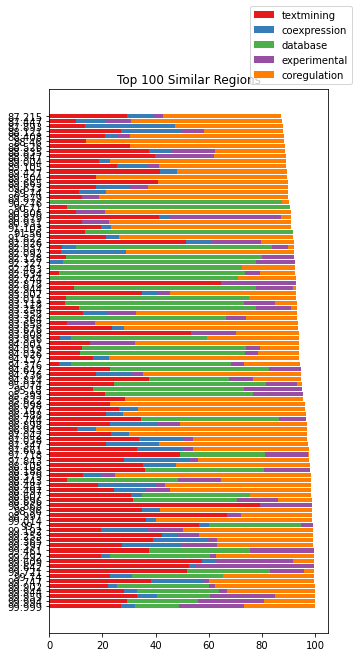

In [33]:
width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(5, 10))
# labels = top100_combined_df.index[:100]
labels = total[:100]
# print(top100_combined_df[1:9])

colors = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']

for i, c in enumerate(columns):
    if i == 0:
        ax.barh(labels, ((top100_combined_df[c+'_fraction'])[:100]/10), width, label=c, color=colors[i])
        summed_left = (top100_combined_df[c+'_fraction'])[:100]/10
    else:
#         print(summed_left)
        ax.barh(labels, ((top100_combined_df[c+'_fraction'])[:100]/10), width, left=summed_left, label=c, color=colors[i])
        summed_left = summed_left + (top100_combined_df[c+'_fraction'])[:100]/10

# ax.set_ylabel('Scores')
# ax.set_title('Scores by Type')
ax.set_title('Top 100 Similar Regions')
ax.legend(bbox_to_anchor =(0.7, 1))

# for b in bars:
#     ax.bar_label(b, fmt='%.2f')


# for i, v in enumerate(np.array(summed_left[:20])):
#     ax.text(v, i, "{:.2f}".format(v), color='grey', fontweight='bold')

    
total = summed_left.round(3).astype(str)
# print(total)
    

# plt.gca().invert_yaxis()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_GATA1-top100-combined-score-barplot-vertical.svg')

In [131]:
# Check the enrichment scores of the solely coregulation genes
coregulation_only_genes = ['OR10G2', 'IFNA10', 'TEX28', 'OR2L8', 'AGAP4', 'IFNA8', 'CT45A3', 'CT45A10']

# gata1_gene_dhsenrichment.loc['CT45A3']

In [77]:
top100_combined_df.loc[coregulation_only_genes]

,chr,start,end,coexpression,experimental,database,textmining,coregulation,combined_score,total,textmining_fraction,coexpression_fraction,database_fraction,experimental_fraction,coregulation_fraction
OR10G2,chr14,21633835.0,21634940.0,0.0,0.0,0.0,0.0,981.445404,981.445404,981.445404,0.0,0.0,0.0,0.0,981.445404
IFNA10,chr9,21206180.0,21207143.0,0.0,0.0,0.0,0.0,981.445404,981.445404,981.445404,0.0,0.0,0.0,0.0,981.445404
TEX28,chrX,154271264.0,154295211.0,0.0,0.0,0.0,0.0,981.445404,981.445404,981.445404,0.0,0.0,0.0,0.0,981.445404
OR2L8,chr1,247948857.0,247949796.0,0.0,0.0,0.0,0.0,981.445404,981.445404,981.445404,0.0,0.0,0.0,0.0,981.445404
AGAP4,chr10,45827339.0,45853875.0,0.0,0.0,0.0,0.0,981.445404,981.445404,981.445404,0.0,0.0,0.0,0.0,981.445404
IFNA8,chr9,21409116.0,21410185.0,0.0,0.0,0.0,0.0,981.445404,981.445404,981.445404,0.0,0.0,0.0,0.0,981.445404
CT45A3,chrX,135760043.0,135768191.0,0.0,0.0,0.0,0.0,981.445404,981.445404,981.445404,0.0,0.0,0.0,0.0,981.445404
CT45A10,chrX,135881064.0,135893444.0,0.0,0.0,0.0,0.0,981.445404,981.445404,981.445404,0.0,0.0,0.0,0.0,981.445404


In [132]:
gata1_gene_dhsenrichment = pd.read_pickle('../output/GATA1-gene-dhs-enrichment_pearsonr.pkl')
gata1_gene_dhsenrichment = gata1_gene_dhsenrichment.set_index('index')
gata1_gene_dhsenrichment.loc[coregulation_only_genes]

,Tissue invariant,Stromal A,Primitive / embryonic,Stromal B,Lymphoid,Renal / cancer,Placental / trophoblast,Neural,Cardiac,Organ devel. / renal,Pulmonary devel.,Musculoskeletal,Digestive,Vascular / endothelial,Myeloid / erythroid,Cancer / epithelial,GATA1_pearson_corr
index,,,,,,,,,,,,,,,,,
OR10G2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.263091,0.0,0.981445
IFNA10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.263091,0.0,0.981445
TEX28,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.263091,0.0,0.981445
OR2L8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.263091,0.0,0.981445
AGAP4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.263091,0.0,0.981445
IFNA8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.263091,0.0,0.981445
CT45A3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.263091,0.0,0.981445
CT45A10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.263091,0.0,0.981445


In [85]:
sample_metadata = pd.read_pickle('../data/sample_metadata.pkl')

unique_vals = sorted(set(sample_metadata['Vocabulary representative'].dropna().tolist()))
official_order = np.array([15, 13, 10, 14, 4, 12, 9, 7, 2, 8, 11, 5, 3, 16, 6, 1]).astype(int)-1
official_order_vals = []

for i in official_order:
    official_order_vals.append(unique_vals[i])

nums = [str(num) for num in range(1, 17)]

gene_DHS_enrichment = pd.read_csv('../data/gene_ooe_all_WM20181115.txt', delimiter='\t')

gene_DHS_enrichment = gene_DHS_enrichment.rename(columns=dict(zip(nums, official_order_vals)))
gene_DHS_enrichment.loc[coregulation_only_genes]

,Tissue invariant,Stromal A,Primitive / embryonic,Stromal B,Lymphoid,Renal / cancer,Placental / trophoblast,Neural,Cardiac,Organ devel. / renal,Pulmonary devel.,Musculoskeletal,Digestive,Vascular / endothelial,Myeloid / erythroid,Cancer / epithelial
OR10G2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.263091,0.0
IFNA10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.263091,0.0
TEX28,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.263091,0.0
OR2L8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.263091,0.0
AGAP4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.263091,0.0
IFNA8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.263091,0.0
CT45A3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.263091,0.0
CT45A10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.263091,0.0


In [138]:
gata1_string_df[gata1_string_df['gene_names'].isin(coregulation_only_genes)]

,chr,start,end,gene_names,STRING_score,descriptor


In [139]:
gata1_string_df.gene_names

1728    GATA1
0        TAL1
1       ZFPM1
2        LMO2
3        BRD3
        ...  
1723    HMOX1
1724      ATM
1725     CES1
1726    NOBOX
1727       XK
Name: gene_names, Length: 1729, dtype: object

In [179]:
combined_df.loc[coregulation_only_genes]

,chr,start,end,coexpression,experimental,database,textmining,coregulation,combined_score
OR10G2,chr14,21633835.0,21634940.0,0.0,0.0,0.0,0.0,981.445404,981.445404
IFNA10,chr9,21206180.0,21207143.0,0.0,0.0,0.0,0.0,981.445404,981.445404
TEX28,chrX,154271264.0,154295211.0,0.0,0.0,0.0,0.0,981.445404,981.445404
OR2L8,chr1,247948857.0,247949796.0,0.0,0.0,0.0,0.0,981.445404,981.445404
AGAP4,chr10,45827339.0,45853875.0,0.0,0.0,0.0,0.0,981.445404,981.445404
IFNA8,chr9,21409116.0,21410185.0,0.0,0.0,0.0,0.0,981.445404,981.445404
CT45A3,chrX,135760043.0,135768191.0,0.0,0.0,0.0,0.0,981.445404,981.445404
CT45A10,chrX,135881064.0,135893444.0,0.0,0.0,0.0,0.0,981.445404,981.445404


In [180]:
GATA1_gene_enrichments.loc[coregulation_only_genes]

,chr,start,end,gene_names,coregulation
gene_names,,,,,
OR10G2,chr14,21633835,21634940,OR10G2,981.445404
IFNA10,chr9,21206180,21207143,IFNA10,981.445404
TEX28,chrX,154271264,154295211,TEX28,981.445404
OR2L8,chr1,247948857,247949796,OR2L8,981.445404
AGAP4,chr10,45827339,45853875,AGAP4,981.445404
IFNA8,chr9,21409116,21410185,IFNA8,981.445404
CT45A3,chrX,135760043,135768191,CT45A3,981.445404
CT45A10,chrX,135881064,135893444,CT45A10,981.445404


In [184]:
gata1_individual_scores = pd.read_pickle('../data/GATA1_top-STRING-associations-s3-individual.pkl')

gata1_individual_scores = gata1_individual_scores[['protein2_pref', 'coexpression', 'experimental', 'database', 'textmining', 'combined_score']]
gata1_individual_scores = gata1_individual_scores.set_index('protein2_pref')
gata1_individual_scores.loc[coregulation_only_genes]

KeyError: "None of [Index(['OR10G2', 'IFNA10', 'TEX28', 'OR2L8', 'AGAP4', 'IFNA8', 'CT45A3',\n       'CT45A10'],\n      dtype='object', name='protein2_pref')] are in the [index]"

In [189]:
protein_assoc_sub = pd.read_pickle('../data/hg38-protein-associations.pkl')
protein_assoc_sub

,protein2,neighborhood,neighborhood_transferred,fusion,cooccurence,homology,coexpression,coexpression_transferred,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score,protein1_pref,protein2_pref
protein1,,,,,,,,,,,,,,,,,
9606.ENSP00000000233,9606.ENSP00000379496,0,0,0,0,0,0,54,0,0,0,0,103,85,155,ARF5,PDE1C
9606.ENSP00000000233,9606.ENSP00000314067,0,0,0,0,0,0,0,0,180,0,0,0,61,197,ARF5,PAK2
9606.ENSP00000000233,9606.ENSP00000263116,0,0,0,0,0,0,62,0,152,0,0,0,101,222,ARF5,RAB36
9606.ENSP00000000233,9606.ENSP00000361263,0,0,0,0,0,0,0,0,161,0,0,47,58,181,ARF5,RAPGEF1
9606.ENSP00000000233,9606.ENSP00000409666,0,0,0,0,0,60,63,0,213,0,0,0,72,270,ARF5,SUMO3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9606.ENSP00000485678,9606.ENSP00000354800,0,0,0,0,872,213,0,0,0,0,0,0,0,213,OR6Q1,OR5D13
9606.ENSP00000485678,9606.ENSP00000308270,0,0,0,0,899,152,0,0,0,0,0,0,0,151,OR6Q1,OR5B3
9606.ENSP00000485678,9606.ENSP00000335660,0,0,0,0,0,182,0,0,0,0,0,0,0,181,OR6Q1,KRTAP19-2


In [3]:
hg38_protein_assoc_sub = pd.read_pickle('../data/hg38-protein-associations.pkl')
hg38_protein_assoc_sub

,protein2,neighborhood,neighborhood_transferred,fusion,cooccurence,homology,coexpression,coexpression_transferred,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score,protein1_pref,protein2_pref
protein1,,,,,,,,,,,,,,,,,
9606.ENSP00000000233,9606.ENSP00000379496,0,0,0,0,0,0,54,0,0,0,0,103,85,155,ARF5,PDE1C
9606.ENSP00000000233,9606.ENSP00000314067,0,0,0,0,0,0,0,0,180,0,0,0,61,197,ARF5,PAK2
9606.ENSP00000000233,9606.ENSP00000263116,0,0,0,0,0,0,62,0,152,0,0,0,101,222,ARF5,RAB36
9606.ENSP00000000233,9606.ENSP00000361263,0,0,0,0,0,0,0,0,161,0,0,47,58,181,ARF5,RAPGEF1
9606.ENSP00000000233,9606.ENSP00000409666,0,0,0,0,0,60,63,0,213,0,0,0,72,270,ARF5,SUMO3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9606.ENSP00000485678,9606.ENSP00000354800,0,0,0,0,872,213,0,0,0,0,0,0,0,213,OR6Q1,OR5D13
9606.ENSP00000485678,9606.ENSP00000308270,0,0,0,0,899,152,0,0,0,0,0,0,0,151,OR6Q1,OR5B3
9606.ENSP00000485678,9606.ENSP00000335660,0,0,0,0,0,182,0,0,0,0,0,0,0,181,OR6Q1,KRTAP19-2


In [5]:
hg38_genes = pd.read_pickle('../data/STRING-and-Alex-genes-hg38.pkl')
hg38_genes

,preferred_name,protein_size,annotation
#string_protein_id,,,
9606.ENSP00000000233,ARF5,180,ADP-ribosylation factor 5; GTP-binding protein...
9606.ENSP00000000412,M6PR,277,Cation-dependent mannose-6-phosphate receptor;...
9606.ENSP00000001008,FKBP4,459,Peptidyl-prolyl cis-trans isomerase FKBP4; Imm...
9606.ENSP00000001146,CYP26B1,512,Cytochrome P450 26B1; Involved in the metaboli...
9606.ENSP00000002125,NDUFAF7,441,"Protein arginine methyltransferase NDUFAF7, mi..."
...,...,...,...
9606.ENSP00000485628,SPATA31A5,1347,Spermatogenesis-associated protein 31A5; May p...
9606.ENSP00000485659,MUC5AC,5654,Mucin-5AC; Gel-forming glycoprotein of gastric...
9606.ENSP00000485663,EIF3L,564,Eukaryotic translation initiation factor 3 sub...


In [2]:
pkl_file = pd.read_pickle('../output/dhs_enrichment_25kb.pkl')
pkl_file

[Cancer / epithelial        0.000000
 Cardiac                    0.000000
 Digestive                  0.000000
 Lymphoid                   0.000000
 Musculoskeletal            0.000000
 Myeloid / erythroid        0.000000
 Neural                     0.000000
 Organ devel. / renal       0.000000
 Placental / trophoblast    0.000000
 Primitive / embryonic      0.000000
 Pulmonary devel.           0.000000
 Renal / cancer             0.000000
 Stromal A                  0.000000
 Stromal B                  0.000000
 Tissue invariant           0.634211
 Vascular / endothelial     0.000000
 Name: component, dtype: float64,
 Cancer / epithelial        0.000000
 Cardiac                    0.000000
 Digestive                  0.000000
 Lymphoid                   0.000000
 Musculoskeletal            0.000000
 Myeloid / erythroid        0.000000
 Neural                     0.216686
 Organ devel. / renal       0.000000
 Placental / trophoblast    0.377372
 Primitive / embryonic      0.000000
 Pul

In [3]:
enrichment_df = pd.concat(pkl_file, axis=1).T

In [4]:
enrichment_df

,Cancer / epithelial,Cardiac,Digestive,Lymphoid,Musculoskeletal,Myeloid / erythroid,Neural,Organ devel. / renal,Placental / trophoblast,Primitive / embryonic,Pulmonary devel.,Renal / cancer,Stromal A,Stromal B,Tissue invariant,Vascular / endothelial
component,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.000000,0.0,0.000000,0.634211,0.000000
component,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.216686,0.000000,0.377372,0.0000,0.0,0.000000,0.0,0.000000,0.000000,0.000000
component,0.000000,0.000000,0.691148,0.000000,0.000000,0.000000,0.000000,0.000000,0.754744,0.1596,0.0,0.000000,0.0,0.000000,0.000000,0.000000
component,0.000000,0.000000,0.691148,0.356884,0.461036,0.000000,0.216686,0.000000,0.754744,0.0000,0.0,0.000000,0.0,0.000000,0.000000,0.000000
component,0.000000,0.000000,0.691148,0.356884,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.000000,0.0,0.246975,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
component,0.530514,0.000000,0.691148,0.713768,0.922073,1.607515,0.650059,0.628364,0.000000,0.3192,0.0,5.551979,0.0,0.987900,1.268421,1.178837
component,1.061027,1.682457,1.382296,0.713768,0.461036,2.143353,0.216686,1.256728,0.754744,0.4788,0.0,0.000000,0.0,0.493950,0.634211,2.357673
component,1.591541,0.841229,0.691148,0.356884,0.461036,0.535838,0.216686,0.000000,0.000000,0.1596,0.0,1.387995,0.0,1.234875,1.268421,1.178837
component,0.530514,0.000000,0.691148,0.000000,0.461036,2.143353,0.216686,0.000000,0.377372,0.6384,0.0,1.387995,0.0,0.246975,0.000000,1.178837
